# Классификация изображений в Teachable Machine

Трякин Эрнест, группа 23П-1

## Задание 1. Хот-доги и не хот-доги

Проверяем, как экспортированная модель Teachable Machine различает фотографии с хот-догом и без него.

### 1.1 Подготовка изображений

Обучающие фотографии лежат в папках с окончанием `_train`, проверочные в папках с окончанием `_validation`.

In [1]:
# библиотеки для проверки изображений
from hashlib import sha256
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import seaborn as sns

data_dir = Path('../data/hot_dogs')
model_dir = Path('../models/hot_dogs')
train_folders = ['hot_dog_train', 'not_hot_dog_train']
test_folders = ['hot_dog_validation', 'not_hot_dog_validation']

counts = []
for train_folder, test_folder in zip(train_folders, test_folders):
    counts.append({
        'Класс': 'хот-дог' if train_folder == 'hot_dog_train' else 'не хот-дог',
        'Обучение': len(list((data_dir / train_folder).glob('*.jpg'))),
        'Проверка': len(list((data_dir / test_folder).glob('*.jpg')))
    })

pd.DataFrame(counts)

,Класс,Обучение,Проверка
0,хот-дог,249,250
1,не хот-дог,249,250


В обучающих папках по 249 фотографий на класс. В проверочных по 250.

In [2]:
# ищем точные копии обучающих снимков среди проверочных
train_hashes = {}
for folder in train_folders:
    for path in sorted((data_dir / folder).glob('*.jpg')):
        train_hashes[sha256(path.read_bytes()).digest()] = path

duplicates = {}
for folder in test_folders:
    for path in sorted((data_dir / folder).glob('*.jpg')):
        digest = sha256(path.read_bytes()).digest()
        if digest in train_hashes:
            duplicates[path] = train_hashes[digest]

pd.DataFrame(
    [(str(test.relative_to(data_dir)), str(train.relative_to(data_dir)))
     for test, train in duplicates.items()],
    columns=['Проверочный файл', 'Копия в обучении']
)

,Проверочный файл,Копия в обучении
0,not_hot_dog_validation/76271.jpg,not_hot_dog_train/97656.jpg


Файл `76271.jpg` совпадает с обучающим `97656.jpg` байт в байт. Посчитаем прогноз для всех проверочных файлов и исключим эту фотографию из оценки на новых снимках.

### 1.2 Обучение в Teachable Machine

В стандартный проект с изображениями загрузили по 249 фотографий на класс. Оставили 50 эпох, размер пакета 16 и скорость обучения 0.001. Сохранили модель в формате Keras вместе с метками.

![Точность по классам в Teachable Machine](../data/hot_dogs/teachable_machine_accuracy.png)

На внутренней проверке сервис распознал 31 хот-дог из 38 (82%) и 35 снимков без хот-дога из 38 (92%).

### 1.3 Проверка в Teachable Machine

В разделе «Посмотреть» выбрали ввод из файла. По очереди загрузили первые 11 хот-догов и первые 10 снимков без хот-дога по имени файла.

![Проверка фотографии хот-дога](../data/hot_dogs/preview_hot_dog.png)
![Проверка фотографии без хот-дога](../data/hot_dogs/preview_not_hot_dog.png)

In [3]:
# результаты проверки через окно просмотра
preview_results = pd.read_csv(data_dir / 'tm_preview.csv')
preview_results.round(1)

,Файл,Класс,Прогноз в сервисе,"Оценка сервиса, %"
0,133012.jpg,хот-дог,хот-дог,99.4
1,133015.jpg,хот-дог,не хот-дог,82.0
2,133245.jpg,хот-дог,хот-дог,100.0
3,135628.jpg,хот-дог,хот-дог,100.0
4,138933.jpg,хот-дог,хот-дог,100.0
5,138937.jpg,хот-дог,хот-дог,100.0
6,138969.jpg,хот-дог,хот-дог,100.0
7,139177.jpg,хот-дог,хот-дог,100.0
8,142835.jpg,хот-дог,не хот-дог,65.2
9,143012.jpg,хот-дог,не хот-дог,92.3


В окне просмотра правильно определились 8 хот-догов из 11 и все 10 снимков без хот-дога. Файл `143012.jpg` модель отнесла к классу «не хот-дог» с уверенностью 92.3%.

### 1.4 Загрузка модели и проверка фотографий в Jupyter

По коду экспорта Teachable Machine приводим снимок к RGB, обрезаем до 224x224 пикселей и переводим значения пикселей в диапазон от -1 до 1. Берём класс с максимальной оценкой модели.

In [4]:
# загружаем модель и классы в порядке из экспорта
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

from tf_keras.models import load_model

model = load_model(model_dir / 'keras_model.h5', compile=False)
labels = [line.split(' ', 1)[1] for line in
          (model_dir / 'labels.txt').read_text(encoding='utf-8').splitlines()]

print(f'Классы модели: {", ".join(labels)}')

Классы модели: хот-дог, не хот-дог


Индекс 0 в выходе модели соответствует хот-догу, индекс 1 соответствует снимку без хот-дога.

In [5]:
# готовим изображение так же, как в коде экспорта
def prepare_image(path):
    with Image.open(path) as photo:
        return ImageOps.fit(photo.convert('RGB'), (224, 224), Image.Resampling.LANCZOS)

In [6]:
# проверяем все изображения партиями по 32
rows = []
for folder, label in zip(test_folders, labels):
    paths = sorted((data_dir / folder).glob('*.jpg'))
    for start in range(0, len(paths), 32):
        batch_paths = paths[start:start + 32]
        images = np.array([np.asarray(prepare_image(path)) for path in batch_paths], dtype=np.float32)
        probabilities = model(images / 127.5 - 1, training=False).numpy()

        for path, scores in zip(batch_paths, probabilities):
            index = scores.argmax()
            rows.append({
                'Путь': path,
                'Файл': path.name,
                'Класс': label,
                'Прогноз': labels[index],
                'Уверенность, %': float(scores[index] * 100),
                'Верно': labels[index] == label
            })

results = pd.DataFrame(rows)
test_results = results[~results['Путь'].isin(duplicates)]

Смотрим прогнозы Jupyter для тех же 21 файлов, которые загрузили через окно просмотра.

In [7]:
# сравниваем прогнозы сервиса и Jupyter
examples = preview_results.merge(results, on=['Файл', 'Класс'])
examples['Совпали'] = examples['Прогноз в сервисе'] == examples['Прогноз']

examples[['Файл', 'Класс', 'Прогноз в сервисе', 'Прогноз', 'Совпали']]

,Файл,Класс,Прогноз в сервисе,Прогноз,Совпали
0,133012.jpg,хот-дог,хот-дог,хот-дог,True
1,133015.jpg,хот-дог,не хот-дог,не хот-дог,True
2,133245.jpg,хот-дог,хот-дог,хот-дог,True
3,135628.jpg,хот-дог,хот-дог,хот-дог,True
4,138933.jpg,хот-дог,хот-дог,хот-дог,True
5,138937.jpg,хот-дог,хот-дог,хот-дог,True
6,138969.jpg,хот-дог,хот-дог,хот-дог,True
7,139177.jpg,хот-дог,хот-дог,хот-дог,True
8,142835.jpg,хот-дог,не хот-дог,хот-дог,False
9,143012.jpg,хот-дог,не хот-дог,не хот-дог,True


На 20 из 21 снимка класс совпал. Для `142835.jpg` сервис выбрал «не хот-дог», а Jupyter выбрал «хот-дог». При изменении размера браузер и Pillow по-разному пересчитывают пиксели.

### 1.5 Точность на всех проверочных фотографиях

In [8]:
# сравниваем точность до и после исключения дубля
metrics = []
for name, table in [('Все файлы', results), ('Без дубля', test_results)]:
    for label in labels + ['Все классы']:
        group = table if label == 'Все классы' else table[table['Класс'] == label]
        metrics.append({
            'Выборка': name,
            'Класс': label,
            'Снимков': len(group),
            'Верно': int(group['Верно'].sum()),
            'Точность, %': group['Верно'].mean() * 100
        })

pd.DataFrame(metrics).round(2)

,Выборка,Класс,Снимков,Верно,"Точность, %"
0,Все файлы,хот-дог,250,211,84.40
1,Все файлы,не хот-дог,250,222,88.80
2,Все файлы,Все классы,500,433,86.60
3,Без дубля,хот-дог,250,211,84.40
4,Без дубля,не хот-дог,249,221,88.76
5,Без дубля,Все классы,499,432,86.57


Модель правильно определила 433 из 500 снимков (86.60%). Один из снимков совпал с файлом в папке обучения. После его исключения осталось 432 верных прогноза из 499 (86.57%).

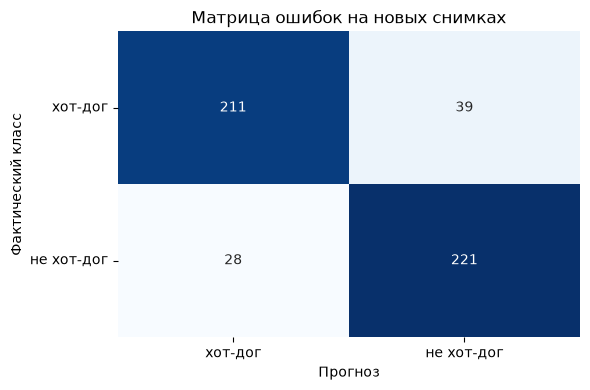

In [9]:
# матрица ошибок на проверке без дубля
confusion = pd.crosstab(test_results['Класс'], test_results['Прогноз'])
confusion = confusion.reindex(index=labels, columns=labels, fill_value=0)

plt.figure(figsize=(6, 4))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Матрица ошибок на новых снимках')
plt.xlabel('Прогноз')
plt.ylabel('Фактический класс')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Модель пропустила 39 хот-догов, а 28 снимков без хот-дога приняла за хот-доги.

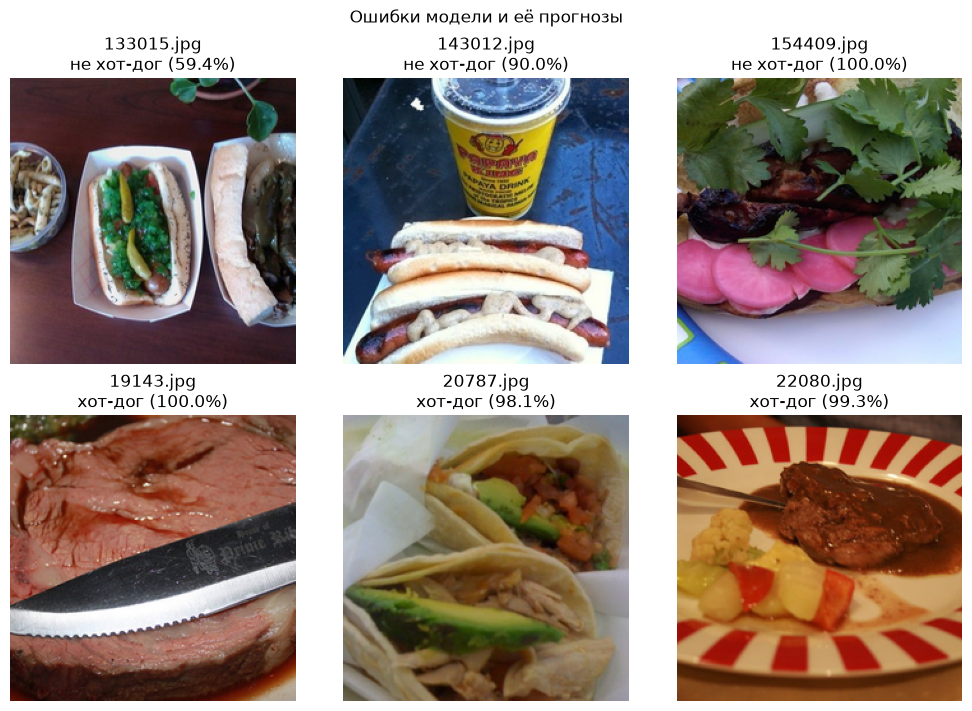

In [10]:
# показываем по три ошибки каждого класса
wrong = test_results[~test_results['Верно']].groupby('Класс', sort=False).head(3)
fig, axes = plt.subplots(2, 3, figsize=(10, 7), layout='constrained')
for ax, (_, row) in zip(axes.flat, wrong.iterrows()):
    ax.imshow(prepare_image(row['Путь']))
    ax.set_title(f"{row['Файл']}\n{row['Прогноз']} ({row['Уверенность, %']:.1f}%)")
    ax.set_axis_off()

fig.suptitle('Ошибки модели и её прогнозы')
plt.show()

На `143012.jpg` вместе с хот-догами в кадре есть стакан, а на `154409.jpg` сосиска частично закрыта зеленью. Среди ложных срабатываний оказались мясо крупным планом и лепёшки с начинкой.

### 1.6 Вывод

На 499 новых снимках точность составила 86.57%. Если всегда отвечать самым частым классом, получилось бы 50.10%. На всех 500 фотографиях новый запуск дал 86.60%, в примере преподавателя было 88.00%. В отчёте используются результаты нового обучения.

## Задание 2. Разъёмы USB-A, USB-C и HDMI

По фотографии определяем тип штекера. В класс HDMI входят полноразмерные штекеры. USB-A отличается прямоугольной формой, USB-C уже и с закруглёнными углами, а у HDMI два угла скошены.

### 2.1 Сбор изображений

Фотографии взяли с Wikimedia Commons. Кадрировали их так, чтобы в кадре был виден нужный штекер. Ссылки на оригиналы, авторов и лицензии записали в `sources.csv`.

In [11]:
# пути к фотографиям и количество снимков
data_dir = Path('../data/connectors')
model_dir = Path('../models/connectors')
folders = {'USB-A': 'usb_a', 'USB-C': 'usb_c', 'HDMI': 'hdmi'}

counts = []
for label, folder in folders.items():
    counts.append({
        'Класс': label,
        'Обучение': len(list((data_dir / 'train' / folder).glob('*.jpg'))),
        'Проверка': len(list((data_dir / 'test' / folder).glob('*.jpg')))
    })

pd.DataFrame(counts)

,Класс,Обучение,Проверка
0,USB-A,20,5
1,USB-C,20,5
2,HDMI,20,5


В каждом классе по 20 обучающих и 5 проверочных фотографий. Схожие кадры из одной серии оставили в одной выборке.

In [12]:
# проверяем, пересекаются ли исходники и файлы между выборками
sources = pd.read_csv(data_dir / 'sources.csv')
train_sources = sources[sources['Файл'].str.startswith('train/')]
test_sources = sources[sources['Файл'].str.startswith('test/')]

shared_sources = set(train_sources['Страница оригинала']) & set(test_sources['Страница оригинала'])
train_hashes = {sha256(path.read_bytes()).digest() for path in (data_dir / 'train').rglob('*.jpg')}
test_hashes = {sha256(path.read_bytes()).digest() for path in (data_dir / 'test').rglob('*.jpg')}

print(f'Совпадений по источникам: {len(shared_sources)}')
print(f'Совпадений по файлам: {len(train_hashes & test_hashes)}')

Совпадений по источникам: 0
Совпадений по файлам: 0


Среди 15 проверочных фотографий нет точных копий и повторов страниц с обучающими снимками.

### 2.2 Обучение в Teachable Machine

В стандартный проект с изображениями загрузили три папки из `train`. Оставили настройки сервиса: 50 эпох, пакет из 16 изображений и скорость обучения 0.001.

![Классы и фотографии в Teachable Machine](../data/connectors/teachable_machine_classes.png)

![Точность по классам в Teachable Machine](../data/connectors/teachable_machine_accuracy.png)

На внутренней проверке сервис правильно распознал 2 из 3 USB-A (67%), 2 из 3 USB-C (67%) и все 3 HDMI (100%).

### 2.3 Загрузка модели и проверка на новых фотографиях

Сохранили экспорт Keras и список меток. Для проверки подготовили фотографии как в коде экспорта: RGB, размер 224x224 и значения пикселей от -1 до 1.

In [13]:
# загружаем экспорт Keras и метки
model = load_model(model_dir / 'keras_model.h5', compile=False)
labels = [line.split(' ', 1)[1] for line in
          (model_dir / 'labels.txt').read_text(encoding='utf-8').splitlines()]

print(f'Классы модели: {", ".join(labels)}')

Классы модели: USB-A, USB-C, HDMI


На выходе модели три оценки в порядке USB-A, USB-C, HDMI.

In [14]:
# загружаем проверочные фотографии
paths = []
true_labels = []
images = []

for label, folder in folders.items():
    for path in sorted((data_dir / 'test' / folder).glob('*.jpg')):
        images.append(np.asarray(prepare_image(path), dtype=np.float32))
        paths.append(path)
        true_labels.append(label)

images = np.array(images)

In [15]:
# прогнозируем класс для каждого штекера
scores = model(images / 127.5 - 1, training=False).numpy()
results = pd.DataFrame({
    'Файл': [path.name for path in paths],
    'Класс': true_labels,
    'Прогноз': [labels[index] for index in scores.argmax(axis=1)],
    'Уверенность, %': scores.max(axis=1).astype(float) * 100
})
results['Верно'] = results['Класс'] == results['Прогноз']

results[['Файл', 'Класс', 'Прогноз', 'Уверенность, %']].round(1)

,Файл,Класс,Прогноз,"Уверенность, %"
0,usb_a_01.jpg,USB-A,USB-A,98.5
1,usb_a_02.jpg,USB-A,USB-A,81.6
2,usb_a_03.jpg,USB-A,USB-A,98.4
3,usb_a_04.jpg,USB-A,USB-A,86.6
4,usb_a_05.jpg,USB-A,USB-A,100.0
5,usb_c_01.jpg,USB-C,USB-C,68.3
6,usb_c_02.jpg,USB-C,USB-C,97.5
7,usb_c_03.jpg,USB-C,USB-C,94.2
8,usb_c_04.jpg,USB-C,USB-C,99.7
9,usb_c_05.jpg,USB-C,HDMI,99.7


Из 15 новых фотографий модель правильно определила 11. На `usb_c_05.jpg` она выбрала HDMI с уверенностью 99.7%.

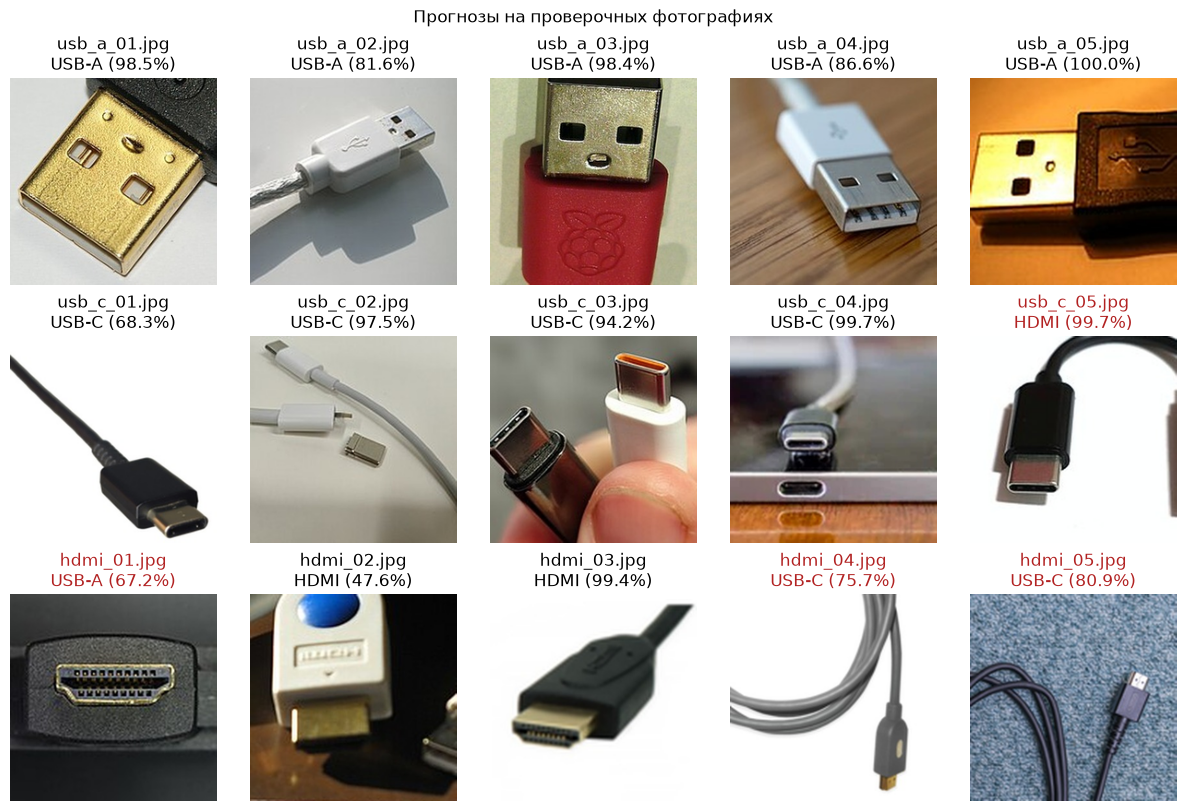

In [16]:
# показываем фотографии и предсказанные классы
fig, axes = plt.subplots(3, 5, figsize=(12, 8), layout='constrained')

for ax, image, (_, row) in zip(axes.flat, images, results.iterrows()):
    color = 'black' if row['Верно'] else 'firebrick'
    ax.imshow(image.astype(np.uint8))
    ax.set_title(f"{row['Файл']}\n{row['Прогноз']} ({row['Уверенность, %']:.1f}%)", color=color)
    ax.set_axis_off()

fig.suptitle('Прогнозы на проверочных фотографиях')
plt.show()

Два HDMI, определённые как USB-C, сняты с расстояния. Штекеры занимают небольшую часть кадра, а форма торца плохо видна.

### 2.4 Точность по классам

In [17]:
# считаем долю правильных прогнозов
metrics = results.groupby('Класс', sort=False)['Верно'].agg(Снимков='size', Верно='sum')
metrics.loc['Все классы'] = [len(results), results['Верно'].sum()]
metrics['Точность, %'] = metrics['Верно'] / metrics['Снимков'] * 100

metrics.round(2)

,Снимков,Верно,"Точность, %"
Класс,,,
USB-A,5,5,100.00
USB-C,5,4,80.00
HDMI,5,2,40.00
Все классы,15,11,73.33


USB-A распознаны на 5 из 5 снимков, USB-C на 4 из 5, HDMI на 2 из 5. Общая точность составила 73.33%.

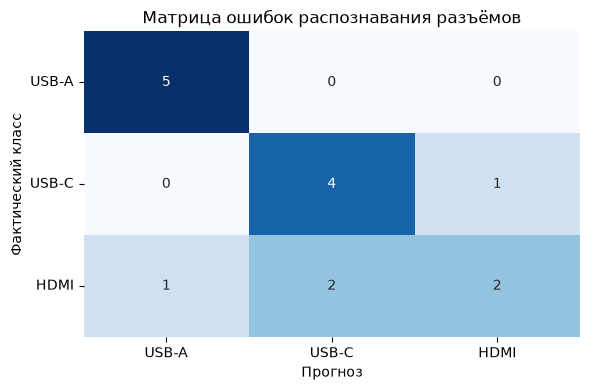

In [18]:
# матрица ошибок на новых фотографиях
confusion = pd.crosstab(results['Класс'], results['Прогноз'])
confusion = confusion.reindex(index=list(folders), columns=list(folders), fill_value=0)

plt.figure(figsize=(6, 4))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Матрица ошибок распознавания разъёмов')
plt.xlabel('Прогноз')
plt.ylabel('Фактический класс')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Из трёх ошибок на HDMI два снимка ушли в USB-C и один в USB-A. Ещё один USB-C модель приняла за HDMI.

### 2.5 Вывод

На новых снимках лучше всего распознавался USB-A, сложнее всего HDMI. На всей проверке получилось 11 верных ответов из 15. Ответ одним и тем же классом дал бы 5 из 15 (33.33%). На каждом классе проверили по 5 снимков, поэтому одна ошибка меняет точность класса на 20 процентных пунктов.

## Задание 4. API и приложение с графическим интерфейсом

Подключили модель разъёмов из задания 2 к FastAPI. Интерфейс на Streamlit отправляет фото на `POST /predict` и показывает полученный класс и уверенность модели для снимка. Точность на всей выборке рассчитана в разделе 2.4.
